# Premier League Simulation — Performance Analysis
Task D: baseline comparison, parallel execution times, and speedup.

Note: these are preliminary results. The baseline and parallel runs use different season counts, so direct speedup is not yet valid.

In [1]:
import csv
import matplotlib.pyplot as plt
from pathlib import Path

root = Path('..')
baseline_path = root / 'results/array/baseline-100k/timing.csv'
parallel_path = root / 'results/array/job-30256/timing_all_tasks.csv'

with baseline_path.open() as f:
    baseline = next(csv.DictReader(f))
with parallel_path.open() as f:
    tasks = list(csv.DictReader(f))

print('Baseline seasons:', baseline['seasons'])
print('Parallel seasons per task:', [r['seasons'] for r in tasks])
print('Baseline simulation time:', baseline['simulation_seconds'])
print('Parallel task times:', [r['simulation_seconds'] for r in tasks])

Baseline seasons: 100000
Parallel seasons per task: ['25000', '25000', '25000', '25000']
Baseline simulation time: 6.767281593289226
Parallel task times: ['1.53570598596707', '1.5393382390029728', '1.532631245907396', '1.6842268067412078']


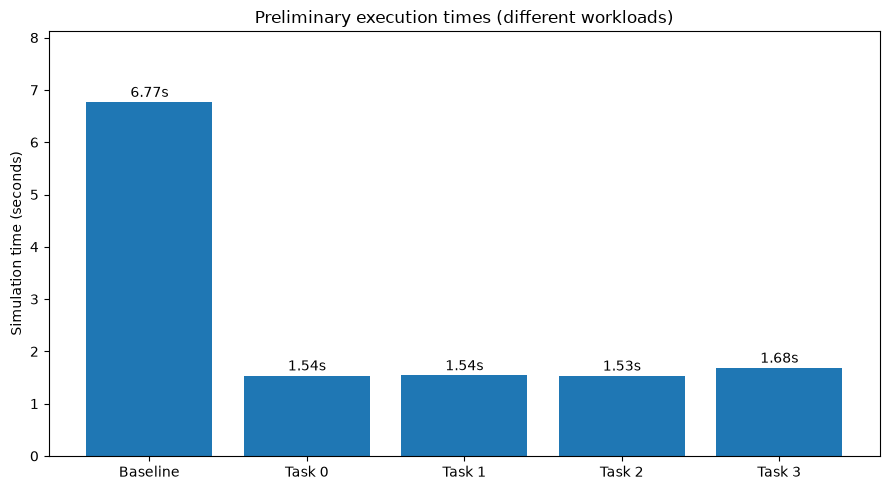

In [2]:
labels = ['Baseline'] + [f'Task {r["task_id"]}' for r in tasks]
times = [float(baseline['simulation_seconds'])] + [float(r['simulation_seconds']) for r in tasks]

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, times)
plt.ylabel('Simulation time (seconds)')
plt.title('Preliminary execution times (different workloads)')
for bar, value in zip(bars, times):
    plt.text(bar.get_x() + bar.get_width()/2, value + 0.1, f'{value:.2f}s', ha='center')
plt.ylim(0, max(times)*1.2)
plt.tight_layout()
plt.show()

In [3]:
%pip install matplotlib


[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: /home/pc48/plot-env/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install --user matplotlib

ERROR: Can not perform a '--user' install. User site-packages are not visible in this virtualenv.

[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: /home/pc48/plot-env/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import csv
from pathlib import Path

root = Path("..")

with open(root / "results/baseline-100k-test/timing.csv") as f:
    baseline = next(csv.DictReader(f))

with open(root / "results/array-100k-test/timing_all_tasks.csv") as f:
    tasks = list(csv.DictReader(f))

sequential_time = float(baseline["simulation_seconds"])
parallel_time = max(float(task["simulation_seconds"]) for task in tasks)

speedup = sequential_time / parallel_time
ideal_speedup = 4
efficiency = speedup / ideal_speedup

print(f"Sequential simulation time: {sequential_time:.2f} s")
print(f"Parallel maximum task time: {parallel_time:.2f} s")
print(f"Preliminary speedup: {speedup:.2f}x")
print(f"Ideal speedup for 4 workers: {ideal_speedup:.2f}x")
print(f"Conditional efficiency (4 workers): {efficiency:.1%}")

Sequential simulation time: 7.41 s
Parallel maximum task time: 5.02 s
Preliminary speedup: 1.48x
Ideal speedup for 4 workers: 4.00x
Conditional efficiency (4 workers): 36.9%


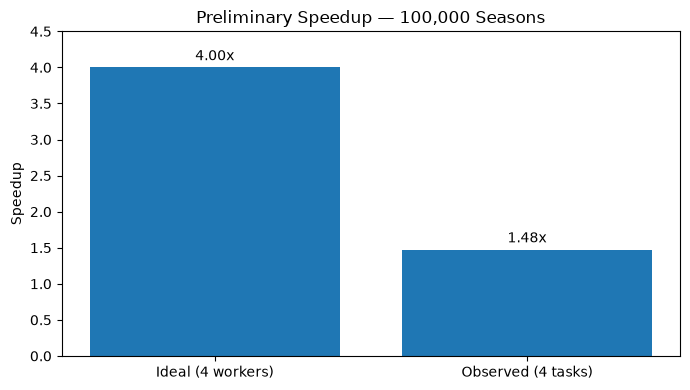

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(["Ideal (4 workers)", "Observed (4 tasks)"],
        [4, speedup])

plt.ylabel("Speedup")
plt.title("Preliminary Speedup — 100,000 Seasons")
plt.ylim(0, 4.5)

for i, value in enumerate([4, speedup]):
    plt.text(i, value + 0.1, f"{value:.2f}x", ha="center")

plt.tight_layout()
plt.show()

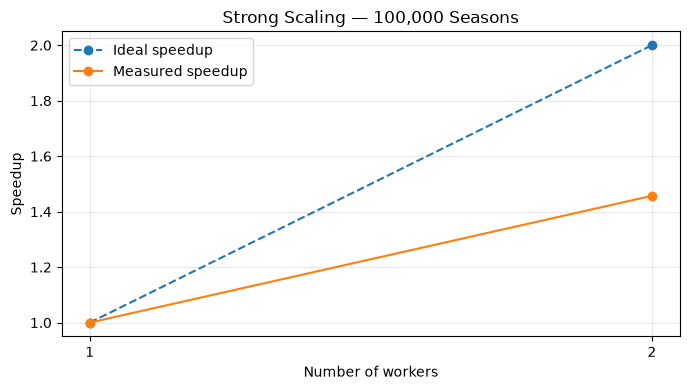

1 worker(s): 7.42s | Speedup: 1.00x | Efficiency: 100.0%
2 worker(s): 5.09s | Speedup: 1.46x | Efficiency: 72.9%


In [7]:
import csv
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("..")
workers = [1, 2]
times = []

for w in workers:
    with open(root / f"results/scaling-pool-{w}w/timing.csv") as f:
        row = next(csv.DictReader(f))
        times.append(float(row["simulation_seconds"]))

speedups = [times[0] / t for t in times]
efficiencies = [100 * s / w for s, w in zip(speedups, workers)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(workers, workers, "o--", label="Ideal speedup")
ax.plot(workers, speedups, "o-", label="Measured speedup")
ax.set_xticks(workers)
ax.set_xlabel("Number of workers")
ax.set_ylabel("Speedup")
ax.set_title("Strong Scaling — 100,000 Seasons")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

for w, t, s, e in zip(workers, times, speedups, efficiencies):
    print(f"{w} worker(s): {t:.2f}s | Speedup: {s:.2f}x | Efficiency: {e:.1f}%")

# Strong Scaling Results and Interpretation

We tested the Premier League simulation by running it 100,000 times and saw how it worked with one or two workers doing the job at the same time.

The single-worker version took 7.42 seconds to finish, but the 2-worker version was faster, completing in just 5.09 seconds. This means it was 1.46 times quicker. It also had a parallel efficiency of 72.9%.

The two versions gave the same results as the standard one done step by step, which showed they were correct.

The speedup we saw was not as high as it could be, which is twice as fast. This is probably because managing processes and coordinating tasks takes some time, and some parts of the simulation still have to run one after the other.

We tried using 4 workers, but the system would only let us use 2 CPUs for each task. So, we can't give a good measurement for 4 workers from this test.

These results are based on initial tests in our current setup. To get a better sense of how things work on a larger scale, we would need to do more experiments in a controlled environment and take more measurements. This would give us a more complete picture.